##  4.1 to train and evaluate a neural network using the IMDB movie reviews dataset. 

In [ ]:
# # # Step 1 Loading the IMDB Dataset
from tensorflow.keras.datasets import imdb

(train_data, train_labels), (test_data, test_labels) = imdb.load_data(num_words=10000)
print(f"Training samples: {len(train_data)}, Testing samples: {len(test_data)}")



17464789/17464789 [==============================] - 6s 0us/step
Training samples: 25000, Testing samples: 25000


In [ ]:
# # #  Step 2 Preprocessing the Data


import numpy as np

def vectorize_sequences(sequences, dimension=10000):
    results = np.zeros((len(sequences), dimension))
    for i, sequence in enumerate(sequences):
        results[i, sequence] = 1.0
    return results
x_train = vectorize_sequences(train_data)
x_test = vectorize_sequences(test_data)
y_train = np.asarray(train_labels).astype("float32")
y_test = np.asarray(test_labels).astype("float32")


In [ ]:
# # # Step 3 Building the Model
from tensorflow import keras
from tensorflow.keras import layers

# Define the model
model = keras.Sequential([
    layers.Dense(16, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

# Step 4 Compile the model
model.compile(optimizer="rmsprop",
              loss="binary_crossentropy",
              metrics=["accuracy"])


In [ ]:
# # # Step 5 Creating a Validation Set
# # #  Set aside 10,000 samples for validation
x_val = x_train[:10000]
partial_x_train = x_train[10000:]

y_val = y_train[:10000]
partial_y_train = y_train[10000:]


In [ ]:
# # # Step 6 Training the Model
history = model.fit(partial_x_train,
                    partial_y_train,
                    epochs=20,
                    batch_size=512,
                    validation_data=(x_val, y_val))


Epoch 1/20


30/30 [==============================] - 3s 44ms/step - loss: 0.5463 - accuracy: 0.7599 - val_loss: 0.4297 - val_accuracy: 0.8547
Epoch 2/20
30/30 [==============================] - 0s 13ms/step - loss: 0.3373 - accuracy: 0.8931 - val_loss: 0.3465 - val_accuracy: 0.8613
Epoch 3/20
30/30 [==============================] - 0s 12ms/step - loss: 0.2512 - accuracy: 0.9190 - val_loss: 0.3217 - val_accuracy: 0.8690
Epoch 4/20
30/30 [==============================] - 0s 11ms/step - loss: 0.2026 - accuracy: 0.9338 - val_loss: 0.2760 - val_accuracy: 0.8906
Epoch 5/20
30/30 [==============================] - 0s 11ms/step - loss: 0.1688 - accuracy: 0.9455 - val_loss: 0.2747 - val_accuracy: 0.8880
Epoch 6/20
30/30 [==============================] - 0s 11ms/step - loss: 0.1412 - accuracy: 0.9562 - val_loss: 0.3323 - val_accuracy: 0.8690
Epoch 7/20
30/30 [==============================] - 0s 11ms/step - loss: 0.1230 - accuracy: 0.9623 - val_loss: 0.2974 - val_accuracy: 0.8837
Epoch 8/20


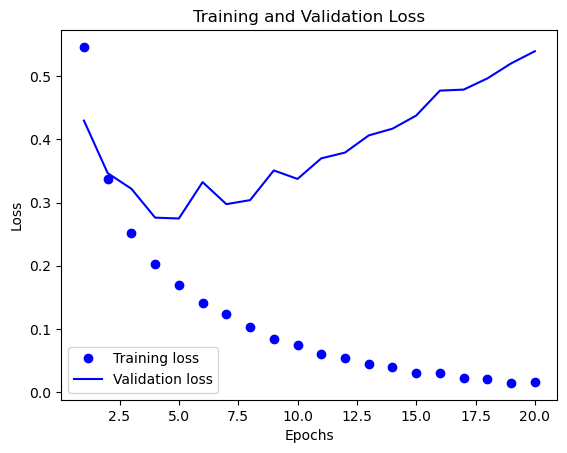

In [ ]:
# # # Step 7 Plotting Training and Validation Loss
import matplotlib.pyplot as plt

history_dict = history.history
loss = history_dict["loss"]
val_loss = history_dict["val_loss"]

epochs = range(1, len(loss) + 1)

plt.plot(epochs, loss, "bo", label="Training loss")  
plt.plot(epochs, val_loss, "b", label="Validation loss")  
plt.title("Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()


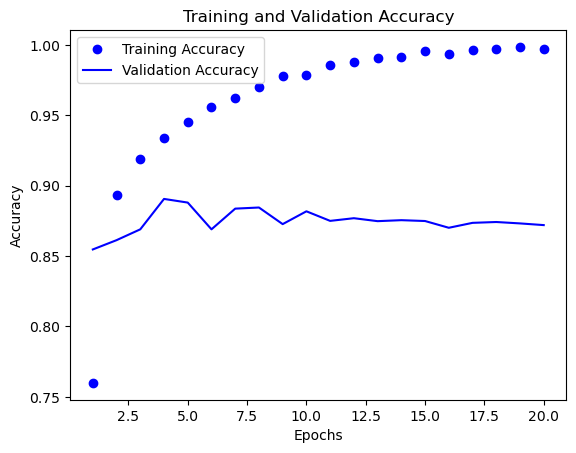

In [ ]:
# # #  Step 8 Plotting Training and Validation Accuracy
plt.clf()  
acc = history_dict["accuracy"]
val_acc = history_dict["val_accuracy"]

plt.plot(epochs, acc, "bo", label="Training Accuracy")  
plt.plot(epochs, val_acc, "b", label="Validation Accuracy")  
plt.title("Training and Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()


In [ ]:
# # # Step 9 Rebuilding and retrain model for 4 epochs (to prevent overfitting)
model = keras.Sequential([
    layers.Dense(16, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

model.compile(optimizer="rmsprop",
              loss="binary_crossentropy",
              metrics=["accuracy"])

model.fit(x_train, y_train, epochs=4, batch_size=512)


Epoch 1/4
49/49 [==============================] - 1s 6ms/step - loss: 0.4736 - accuracy: 0.8184
Epoch 2/4
49/49 [==============================] - 0s 7ms/step - loss: 0.2853 - accuracy: 0.9016
Epoch 3/4
49/49 [==============================] - 0s 6ms/step - loss: 0.2238 - accuracy: 0.9195
Epoch 4/4
49/49 [==============================] - 0s 6ms/step - loss: 0.1892 - accuracy: 0.9330


In [ ]:
# # # Step 10 Evaluating the Model on Test Data
results = model.evaluate(x_test, y_test)
print(f"Test Loss: {results[0]}, Test Accuracy: {results[1]}")


782/782 [==============================] - 2s 2ms/step - loss: 0.2803 - accuracy: 0.8877
Test Loss: 0.2803255021572113, Test Accuracy: 0.8876799941062927


In [ ]:
# # # Step 11 Generating Predictions on New Data


predictions = model.predict(x_test)


print(predictions[:5])


782/782 [==============================] - 1s 2ms/step
[[0.19247277]
 [0.999043  ]
 [0.93610716]
 [0.8612471 ]
 [0.959336  ]]


 ## Follow the steps described in section 4.2 to train and evaluate a neural network using the Reuters dataset

In [11]:
# # # Step 1 Loading the Reuters Dataset

from tensorflow.keras.datasets import reuters

# Load dataset, keeping only the top 10,000 most frequent words
(train_data, train_labels), (test_data, test_labels) = reuters.load_data(num_words=10000)

# Check the number of samples
print(f"Training samples: {len(train_data)}, Testing samples: {len(test_data)}")

2110848/2110848 [==============================] - 1s 0us/step
Training samples: 8982, Testing samples: 2246


In [12]:
 # # # Step 2: Preprocessing - Vectorizing the Data

import numpy as np

def vectorize_sequences(sequences, dimension=10000):
    results = np.zeros((len(sequences), dimension))
    for i, sequence in enumerate(sequences):
        results[i, sequence] = 1.0
    return results
x_train = vectorize_sequences(train_data)
x_test = vectorize_sequences(test_data)

In [13]:
# # # Step 3: Preprocessing - One-Hot Encoding Labels

from tensorflow.keras.utils import to_categorical
y_train = to_categorical(train_labels)
y_test = to_categorical(test_labels)

In [ ]:
 # # # Step 4: Building the Model

from tensorflow import keras
from tensorflow.keras import layers


model = keras.Sequential([
    layers.Dense(64, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(46, activation="softmax") 
])

model.compile(optimizer="rmsprop",
              loss="categorical_crossentropy",
              metrics=["accuracy"])

In [15]:
 # # # Step 5: Creating a Validation Set
x_val = x_train[:1000]
partial_x_train = x_train[1000:]

y_val = y_train[:1000]
partial_y_train = y_train[1000:]

In [16]:
# # #  Step 6: Training the Model

history = model.fit(partial_x_train,
                    partial_y_train,
                    epochs=20,
                    batch_size=512,
                    validation_data=(x_val, y_val))

Epoch 1/20
16/16 [==============================] - 2s 34ms/step - loss: 2.5514 - accuracy: 0.5115 - val_loss: 1.7079 - val_accuracy: 0.6360
Epoch 2/20
16/16 [==============================] - 0s 15ms/step - loss: 1.4569 - accuracy: 0.6896 - val_loss: 1.3045 - val_accuracy: 0.7010
Epoch 3/20
16/16 [==============================] - 0s 16ms/step - loss: 1.1232 - accuracy: 0.7521 - val_loss: 1.1277 - val_accuracy: 0.7370
Epoch 4/20
16/16 [==============================] - 0s 13ms/step - loss: 0.9162 - accuracy: 0.8042 - val_loss: 1.0200 - val_accuracy: 0.7800
Epoch 5/20
16/16 [==============================] - 0s 14ms/step - loss: 0.7575 - accuracy: 0.8364 - val_loss: 0.9467 - val_accuracy: 0.8040
Epoch 6/20
16/16 [==============================] - 0s 14ms/step - loss: 0.6281 - accuracy: 0.8629 - val_loss: 0.9180 - val_accuracy: 0.7950
Epoch 7/20
16/16 [==============================] - 0s 13ms/step - loss: 0.5264 - accuracy: 0.8845 - val_loss: 0.8763 - val_accuracy: 0.8120
Epoch 8/20
16

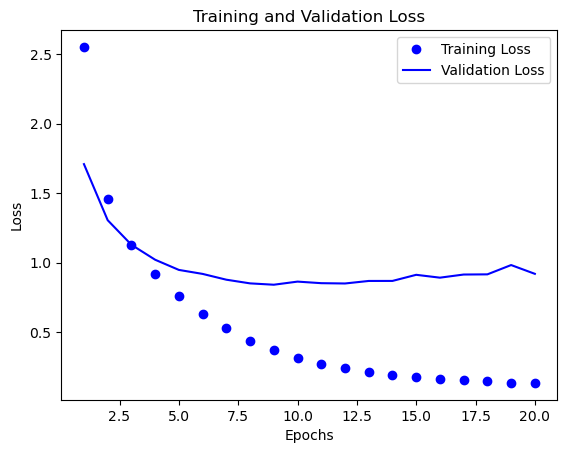

In [17]:
# # # Step 7: Visualizing Training & Validation Loss

import matplotlib.pyplot as plt

history_dict = history.history
loss = history_dict["loss"]
val_loss = history_dict["val_loss"]

epochs = range(1, len(loss) + 1)

plt.plot(epochs, loss, "bo", label="Training Loss")  
plt.plot(epochs, val_loss, "b", label="Validation Loss")  
plt.title("Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

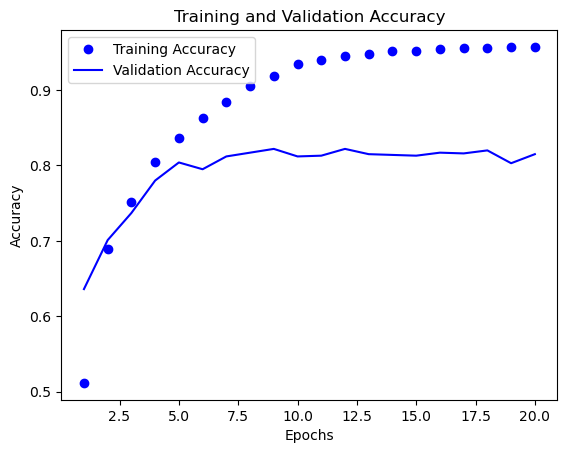

In [18]:
 # # # Step 8: Visualizing Training & Validation Accuracy

plt.clf() 
acc = history_dict["accuracy"]
val_acc = history_dict["val_accuracy"]

plt.plot(epochs, acc, "bo", label="Training Accuracy")  
plt.plot(epochs, val_acc, "b", label="Validation Accuracy")  
plt.title("Training and Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [19]:
# # # Step 9: Retraining Model with Optimal Epochs (9)

model = keras.Sequential([
    layers.Dense(64, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(46, activation="softmax")
])

model.compile(optimizer="rmsprop",
              loss="categorical_crossentropy",
              metrics=["accuracy"])

model.fit(x_train, y_train, epochs=9, batch_size=512)

Epoch 1/9
18/18 [==============================] - 1s 14ms/step - loss: 2.5849 - accuracy: 0.5174
Epoch 2/9
18/18 [==============================] - 0s 11ms/step - loss: 1.4534 - accuracy: 0.6890
Epoch 3/9
18/18 [==============================] - 0s 10ms/step - loss: 1.1291 - accuracy: 0.7512
Epoch 4/9
18/18 [==============================] - 0s 10ms/step - loss: 0.9281 - accuracy: 0.7973
Epoch 5/9
18/18 [==============================] - 0s 13ms/step - loss: 0.7709 - accuracy: 0.8358
Epoch 6/9
18/18 [==============================] - 0s 11ms/step - loss: 0.6410 - accuracy: 0.8638
Epoch 7/9
18/18 [==============================] - 0s 10ms/step - loss: 0.5420 - accuracy: 0.8855
Epoch 8/9
18/18 [==============================] - 0s 10ms/step - loss: 0.4577 - accuracy: 0.9021
Epoch 9/9
18/18 [==============================] - 0s 8ms/step - loss: 0.3870 - accuracy: 0.9164


In [20]:
# # # Step 10: Evaluating the Model on Test Data

results = model.evaluate(x_test, y_test)
print(f"Test Loss: {results[0]}, Test Accuracy: {results[1]}")

71/71 [==============================] - 0s 3ms/step - loss: 0.9246 - accuracy: 0.7881
Test Loss: 0.924580454826355, Test Accuracy: 0.7880676984786987


In [21]:
# # # Step 11: Generating Predictions on New Data

predictions = model.predict(x_test)

print(f"Predicted class for first sample: {np.argmax(predictions[0])}")

71/71 [==============================] - 0s 3ms/step
Predicted class for first sample: 3


## Follow the steps described in section 4.3 to train and evaluate a neural network using the Boston housing dataset.

In [22]:
# # Loading the Boston housing dataset
from tensorflow.keras.datasets import boston_housing

(train_data, train_targets), (test_data, test_targets) = boston_housing.load_data()

# Checking dataset dimensions
print(f"Train data shape: {train_data.shape}")
print(f"Test data shape: {test_data.shape}")

# Displaying some target values (house prices in thousands of dollars)
print(f"Train targets: {train_targets[:10]}")


57026/57026 [==============================] - 0s 2us/step
Train data shape: (404, 13)
Test data shape: (102, 13)
Train targets: [15.2 42.3 50.  21.1 17.7 18.5 11.3 15.6 15.6 14.4]


In [23]:
# # Normalizing the data
import numpy as np

mean = train_data.mean(axis=0)
train_data -= mean
std = train_data.std(axis=0)
train_data /= std

test_data -= mean
test_data /= std

In [24]:
# # Building the model
from tensorflow import keras
from tensorflow.keras import layers

def building_model():
    model = keras.Sequential([
        layers.Dense(64, activation="relu"),
        layers.Dense(64, activation="relu"),
        layers.Dense(1)  # Output layer for regression
    ])
    
    model.compile(optimizer="rmsprop", loss="mse", metrics=["mae"])
    return model


In [25]:
# # Validating the model using K-fold cross-validation
k = 4
num_val_samples = len(train_data) // k
num_epochs = 100
all_scores = []

for i in range(k):
    print(f"Processing fold #{i}")

    # Splitting data for validation
    val_data = train_data[i * num_val_samples: (i + 1) * num_val_samples]
    val_targets = train_targets[i * num_val_samples: (i + 1) * num_val_samples]

    # Training data excluding validation partition
    partial_train_data = np.concatenate(
        [train_data[:i * num_val_samples], train_data[(i + 1) * num_val_samples:]], axis=0)
    
    partial_train_targets = np.concatenate(
        [train_targets[:i * num_val_samples], train_targets[(i + 1) * num_val_samples:]], axis=0)

    model = building_model()
    model.fit(partial_train_data, partial_train_targets, epochs=num_epochs, batch_size=16, verbose=0)
    
    val_mse, val_mae = model.evaluate(val_data, val_targets, verbose=0)
    all_scores.append(val_mae)

# Average validation score
print(f"Mean absolute error across folds: {np.mean(all_scores)}")


Processing fold #0
Processing fold #1
Processing fold #2
Processing fold #3
Mean absolute error across folds: 2.4118993282318115


In [26]:
# # Training the model for more epochs and recording validation history
num_epochs = 500
all_mae_histories = []

for i in range(k):
    print(f"Processing fold #{i}")
    
    val_data = train_data[i * num_val_samples: (i + 1) * num_val_samples]
    val_targets = train_targets[i * num_val_samples: (i + 1) * num_val_samples]

    partial_train_data = np.concatenate(
        [train_data[:i * num_val_samples], train_data[(i + 1) * num_val_samples:]], axis=0)
    
    partial_train_targets = np.concatenate(
        [train_targets[:i * num_val_samples], train_targets[(i + 1) * num_val_samples:]], axis=0)

    model = building_model()
    history = model.fit(partial_train_data, partial_train_targets, validation_data=(val_data, val_targets),
                        epochs=num_epochs, batch_size=16, verbose=0)
    
    mae_history = history.history["val_mae"]
    all_mae_histories.append(mae_history)

# Computing the average of per-epoch validation scores
average_mae_history = [np.mean([x[i] for x in all_mae_histories]) for i in range(num_epochs)]


Processing fold #0
Processing fold #1
Processing fold #2
Processing fold #3


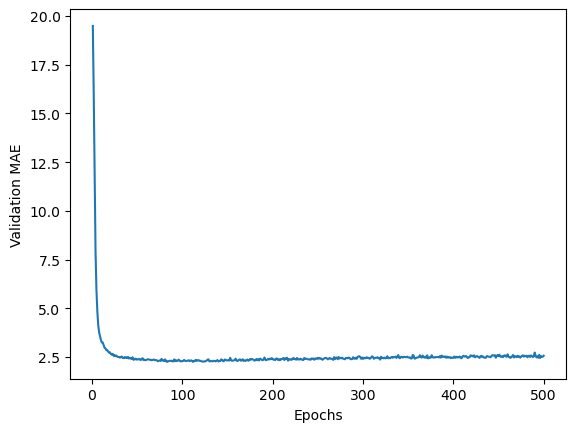

In [27]:
# # Plotting validation scores
import matplotlib.pyplot as plt

plt.plot(range(1, len(average_mae_history) + 1), average_mae_history)
plt.xlabel("Epochs")
plt.ylabel("Validation MAE")
plt.show()


In [28]:
# # Training the final model with best parameters
final_model = building_model()
final_model.fit(train_data, train_targets, epochs=130, batch_size=16, verbose=0)

# Evaluating on test data
test_mse_score, test_mae_score = final_model.evaluate(test_data, test_targets)

print(f"Final test MAE: {test_mae_score}")


4/4 [==============================] - 0s 1ms/step - loss: 18.7520 - mae: 2.9083
Final test MAE: 2.9082648754119873


In [29]:
# # Generating predictions on new data
predictions = final_model.predict(test_data)
print(f"First house price prediction: {predictions[0][0] * 1000:.2f} dollars")


4/4 [==============================] - 0s 3ms/step
First house price prediction: 8415.15 dollars
